### Binary Search Tree 


#### Create / Insert into Binary Search Tree 

Two Approaches 

Approach #1. Recursive Iteration method - O(h) time and O(h) space (Naive Approach) 
Intuition: 
    The idea is to compare the key with the current node and based on the comparision result
    recursively move to the left or the right subtree until an empty position is found 

Steps: 
1. Start from the root node and compare the key with the current node's value 
2. If the key is already present, return the current root without inserting a duplicate
3. If the key is smaller, recursively insert/move to the left subtree 
4. If the key is greater, recurtively move into the right subtree
5. When a nullptr positin is reached, create and insert the new node with the key at that position

Approach #2: [Expected approach] Using iterative traversal - O(h) time and O(1) space

Intuition:
The idea is to compare the key with the current node and based ont he result, iteratively move left or right unitl and empty position is found. 

Steps: 
1. Create a new node temp containing the given key 
2. If the BST is empty, return temp as root 
3. Otherwise start from the root and traverse the BST 
4. If the key is already present, return the root without inserting the duplicate 
5. If the key is smaller than the current node, move to the left subtree 
6. If key key is greater, move to the right subtree 
7. When an appropriate empty position is found, attach the new node as either the left or the right child. 


In [28]:
from collections import deque 

class Node: 
    def __init__(self, value):
        self.data = value 
        self.left = None 
        self.right = None 

def insertRecursive(root, key):
    if root is None:
        return Node(key)

    if key == root.data:
        return root 
    
    if key < root.data:
        root.left = insertRecursive(root.left, key)
    else: 
        root.right = insertRecursive(root.right, key)
    
    return root 

def insertIterative(root, key):
    temp = Node(key)

    # If tree is empty 
    if root is None: 
        return temp 

    curr = root
    parent = None # Track the parent node to attach the new node to
    
    # Step 1: Traverse down to find the correct empty spot (and its parent)
    while curr is not None:
        parent = curr
        if curr.data == key:
            return root  # Value already exists, do nothing
        elif curr.data > key:
            curr = curr.left 
        else: 
            curr = curr.right 

    # Step 2: Attach the new node to the parent
    if parent.data > key: 
        parent.left = temp 
    else: 
        parent.right = temp 

    return root 

def printBST(root):
    """Prints the tree in Level-Order. Truncates trailing 'N's for clean output."""
    if not root:
        print("[]")
        return

    q = deque([root])
    result = []

    while q:
        curr = q.popleft()
        if curr is not None:
            result.append(str(curr.data))
            q.append(curr.left)
            q.append(curr.right)
        else:
            result.append("N")

    # Clean up: Strip out trailing 'N' values at the end of the tree representation
    while result and result[-1] == "N":
        result.pop()

    print("[" + ", ".join(result) + "]")

    
if __name__ == "__main__":
    root = Node(2) 
    root.left = Node(1) 
    root.right = Node(3) 
    root.right.right = Node(6) 

    key = 4 
    root = insertRecursive (root, key)

    print ("Printing the tree as a list")
    printBST(root)


Printing the tree as a list
[2, 1, 3, N, N, N, 6, 4]


### Deletion in a Binary Search Tree 

Deleting a node in a BST means removing target node while ensuring that the tree remains a valid BST. 

There are three possible scnearios 
Case 1: The Node has no children, then simply delete it.  


Case 2: Node has one child (Left or Right Child)
    We remove the node and connect its parent directly to its only child. This way the tree remains valid after the deletion,.


Case 3: Node has two children 

If the target node has two children. TO maintain the BST property, the replacement node can be either:
    
    1. The inorder successor: the smallest value in the right subtree, which is the next greater value than the target node. 

    2. The inorder predecessor: the largest value in the left subtree, which is the next smaller value than the target node. 

Once the replacement node is chosen, we replace the target node's value with that of the node's valu, and then delete the replacement node, which will now fall under case 1 (no children) or case 2 (one child)


In [ ]:
# Delete a node with value x from BST
def delNode(root, x):
    if root is None:
        return root

    if root.data > x:
        root.left = delNode(root.left, x)
    elif root.data < x:
        root.right = delNode(root.right, x)
    else:
        
        # node with 0 or 1  children
        if root.left is None:
            return root.right
        if root.right is None:
            return root.left
        
        #  Node with 2 children
        succ = getSuccessor(root)
        root.data = succ.data
        root.right = delNode(root.right, succ.data)

    return root
# Complesity: Time O(h), Space O(h)

Binary Search Tree Travesals 

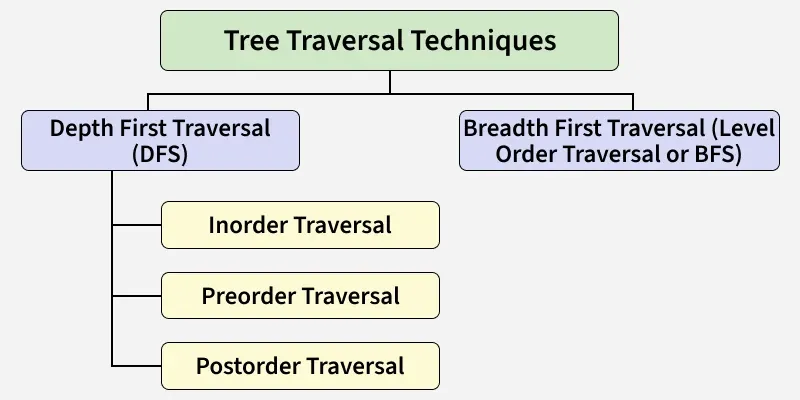

**Depth-First Traversal(DFT)** 

- Explores as far as possible along a branch before exploring the next branch

- Types: Inorder, Preorder, Postorder 

**Breadth-First Traversal (BFT)**

- Explores nodes level by level from top to bottom 

- Type: Level Order Traversal 

Reference: 
https://www.geeksforgeeks.org/dsa/tree-traversals-inorder-preorder-and-postorder/



### Inorder Traversal 

Visits the node: left -> root -> right

Algorithm: 

Traverse the left subtree i.e. call inorder(left->subtree)

Visit the root 

Traverse the right subtree i.e. call inorder(right->subtree)

In [1]:
# InOrder Traversal 

class Node: 
    def __init__(self, value):
        self.data = value 
        self.left = None 
        self.right = None 



if __name__=="__main__":
    root = Node(8)
    root.left = Node(3)
    root.right = Node(10)
    root.left.left = Node(1)
    root.left.right = Node(7)
    root.right.left = Node(9)
    root.right.right = Node(11)
    root.right.right = Node(14)
    root.right.right = Node(17)
    


# Check whether a tree is Balanced 

A balanced tree keeps its height small, so it does not become a long chain. This is particularly important for a Binary Search Tree, because search, insertion, and deletion depend on its height.

1. What does “balanced” mean?
In the common height-balanced binary tree definition:
At every node, the heights of the left and right subtrees differ by at most 1.

abs(left_height - right_height) <= 1

Every node matters—checking only the root is insufficient.

For Ex.

[8, 3, 10, 1, 6, None, 14]

the Tree is Balanced 

| Node | Left subtree height in levels | Right subtree height | Difference |
|---|---:|---:|---:|
| `8` | 2 | 2 | 0 |
| `3` | 1 | 1 | 0 |
| `10` | 0 | 1 | 1 |
| Leaves | 0 | 0 | 0 |


Balanced does not mean both sides must have exactly the same number of nodes.
Also, “balanced” can refer to different formal rules. The height-difference rule above is the usual interview definition and the rule used by AVL trees; other balanced search trees use different guarantees.

Balanced BT versus balanced BST
Balance is about shape. The BST property is about ordering. They are independent.

| Property | What it requires |
|---|---|
| Binary tree | Each node has at most two children |
| Binary search tree | Every value in the left subtree is smaller, and every value in the right subtree is larger, assuming unique values |
| Height-balanced binary tree | Left and right subtree heights differ by at most 1 at every node |
| Height-balanced BST | Satisfies both the ordering and balance conditions |


For example: [10, 20, 5]
This is a balanced binary tree, but not a BST: 20 is on the left of 10, and 5 is on its right.

Conversely, inserting these values into an ordinary BST:
[1, 2, 3, 4, 5]
creates a right-only chain. It is a valid BST but unbalanced.

Why does balance matter?
A balanced binary tree has height O(log n). An unbalanced tree can have height O(n).
For a BST:
| Operation | Balanced BST | Worst-case skewed BST |
|---|---:|---:|
| Search | O(log n) | O(n) |
| Insert | O(log n) | O(n) |
| Delete | O(log n) | O(n) |
| Visit every node | O(n) | O(n) |

With about one million nodes:
- A perfectly balanced BST needs at most roughly 20 node checks for a search.
- A completely skewed BST may need one million.
For an ordinary BT, balance does not make value search O(log n). Without ordering, you may still need to inspect every node.
Balance also affects traversal memory:
- Recursive DFS needs O(h) stack space, so a shallow tree helps.
- BFS needs O(w) queue space, so a wide balanced tree can require a large queue.

How do you check whether a tree is balanced?
Reuse the height calculation you already know, but return -1 when an imbalance is found.

In [ ]:
def is_balanced(root):
    def height(node):
        if node is None:
            return 0

        left_height = height(node.left)
        if left_height == -1:
            return -1

        right_height = height(node.right)
        if right_height == -1:
            return -1

        if abs(left_height - right_height) > 1:
            return -1

        return 1 + max(left_height, right_height)

    return height(root) != -1